<a href="https://colab.research.google.com/github/nikistendo/Niki-Tendolkar-Maker-Portfolio/blob/main/Binary_Classifier.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Pediatric ECG — CNN Binary Classifier
## ZZU pECG Dataset · DISEASE vs OTHER · Google Colab
---
**Study**: Predicting and Classifying Heart Disease in Youths via BPNs & XAI  
**Dataset**: ZZU pECG Dataset (Tan et al., *Scientific Data* 2025)  
**Model**: 1D Convolutional Neural Network (CNN) — PyTorch  
**Task**: Binary classification — DISEASE (cardiovascular) vs OTHER  

### Pipeline overview
1. Setup — unzip dataset, install libraries
2. Load attribute dictionary & create binary labels
3. Drop 9-lead records, filter by signal quality
4. Patient-level train / val / test split
5. PyTorch Dataset & DataLoader with class imbalance weighting
6. CNN architecture
7. Training loop with early stopping
8. Evaluation — accuracy, ROC-AUC, confusion matrix, classification report
9. XAI — SHAP GradientExplainer saliency maps

---
## Section 1 — Setup
### 1.1 Install dependencies

In [ ]:
!pip install wfdb shap seaborn scikit-learn -q
print("Dependencies installed ✓")

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 79.5/79.5 kB 3.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 163.9/163.9 kB 509.2 kB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.9/10.9 MB 124.7 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires pandas==2.2.2, but you have pandas 3.0.1 which is incompatible.
db-dtypes 1.5.0 requires pandas<3.0.0,>=1.5.3, but you have pandas 3.0.1 which is incompatible.
bqplot 0.12.45 requires pandas<3.0.0,>=1.0.0, but you have pandas 3.0.1 which is incompatible.
dask-cudf-cu12 26.2.1 requires pandas<2.4.0,>=2.0, but you have pandas 3.0.1 which is incompatible.
cudf-cu12 26.2.1 requires pandas<2.4.0,>=2.0, but you have pandas 3.0.1 which is incompatible.
gradio 5.50.0 requires pandas<3.0,>=1.0, but you have pandas 3.0.1 which is incompatible.
Dependencies ins

### 1.2 Unzip dataset
Upload `Child_ecg.zip` to Google Drive, then update `ZIP_PATH` below.

In [ ]:
import os

from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
ZIP_PATH    = "/content/drive/MyDrive/Colab Notebooks/md/27078763.zip"
EXTRACT_DIR = '/content/dataset'
ECG_PATH = '/content/dataset/Child_ecg.zip'
EXTRACT_ECG = '/content/dataset/ecg'

!file "{ZIP_PATH}"
stats = os.stat(ZIP_PATH)
print(f"File size: {stats.st_size / (1024 * 1024):.2f} MB")

os.makedirs(EXTRACT_DIR, exist_ok=True)
os.makedirs(EXTRACT_ECG, exist_ok=True)

/content/drive/MyDrive/Colab Notebooks/md/27078763.zip: Zip archive data, at least v1.0 to extract, compression method=store
File size: 3875.36 MB


In [ ]:
print(f"Unzipping {ZIP_PATH} → {EXTRACT_DIR} using 7z...")

# -y assumes 'yes' to all prompts (overwrites)
# -o specifies the output directory
!7z x "{ZIP_PATH}" -o"{EXTRACT_DIR}" -y

print("\nUnzip process finished. Checking contents...")

Unzipping /content/drive/MyDrive/Colab Notebooks/md/27078763.zip → /content/dataset using 7z...

7-Zip [64] 16.02 : Copyright (c) 1999-2016 Igor Pavlov : 2016-05-21
p7zip Version 16.02 (locale=en_US.UTF-8,Utf16=on,HugeFiles=on,64 bits,12 CPUs Intel(R) Xeon(R) CPU @ 2.20GHz (50657),ASM,AES-NI)

Scanning the drive for archives:
  0M Scan /content/drive/MyDrive/Colab Notebooks/md/                                                    1 file, 4063605316 bytes (3876 MiB)

Extracting archive: /content/drive/MyDrive/Colab Notebooks/md/27078763.zip
--
Path = /content/drive/MyDrive/Colab Notebooks/md/27078763.zip
Type = zip
Physical Size = 4063605316

  0%      0% 2 - Child_ecg.zip                        1% 2 - Child_ecg.zip                        2% 2 - Child_ecg.zip            

In [ ]:
print(f"Unzipping {ECG_PATH} → {EXTRACT_ECG} using 7z...")

# -y assumes 'yes' to all prompts (overwrites)
# -o specifies the output directory
!7z x "{ECG_PATH}" -o"{EXTRACT_ECG}" -y

print("\nUnzip process finished. Checking contents...")
# Verify the structure: expecting EXTRACT_DIR/Child_ecg/Pxx/...
if os.path.exists(os.path.join(EXTRACT_ECG, 'Child_ecg')):
    print("Success: 'Child_ecg' folder found.")
else:
    print("Warning: Expected 'Child_ecg' folder not found. Check your ZIP structure.")

Unzipping /content/dataset/Child_ecg.zip → /content/dataset/ecg using 7z...

7-Zip [64] 16.02 : Copyright (c) 1999-2016 Igor Pavlov : 2016-05-21
p7zip Version 16.02 (locale=en_US.UTF-8,Utf16=on,HugeFiles=on,64 bits,12 CPUs Intel(R) Xeon(R) CPU @ 2.20GHz (50657),ASM,AES-NI)

Scanning the drive for archives:
  0M Scan /content/dataset/                           1 file, 1908237306 bytes (1820 MiB)

Extracting archive: /content/dataset/Child_ecg.zip
 10% 4096 Open              --
Path = /content/dataset/Child_ecg.zip
Type = zip
Physical Size = 1908237306
Embedded Stub Size = 4
Total Physical Size = 4055720954
Multivolume = +
Volume Index = 1
Volumes = 2

  0%      0% 157 - Child_ecg/P00/P00041/P00041_E01.dat                                                0% 308 - Child_ecg/P00/P00080/P00080_E01.dat

In [ ]:
print("Unzip complete ✓")
print("Contents:")
for item in sorted(os.listdir(EXTRACT_ECG))[:20]:
    print(f"  {item}")

# Count how many .hea files exist in the extracted directory
total_files = sum([len([f for f in files if f.endswith('.hea')]) for r, d, files in os.walk('/content/dataset/ecg')])
print(f"Extracted records: {total_files} / 14190")

Unzip complete ✓
Contents:
  Child_ecg
Extracted records: 14190 / 14190


Record Name: P00001_E01
Signal Shape: (9000, 9) (samples, leads)
Sampling Frequency: 500 Hz


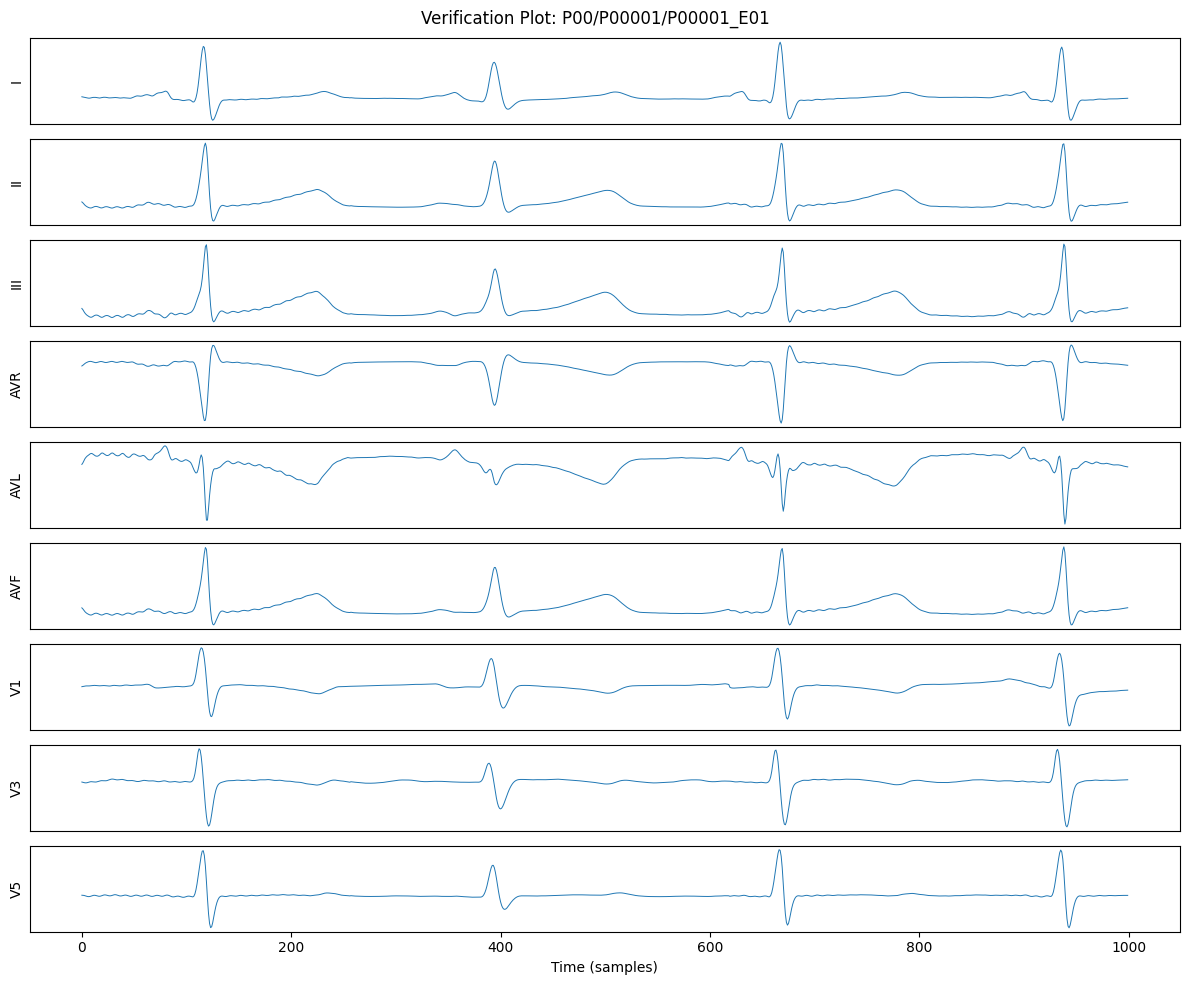

In [ ]:
import wfdb
import matplotlib.pyplot as plt
import numpy as np

# Pick a sample known to be in the first folder (P00)
sample_sub_path = "P00/P00001/P00001_E01"
full_sample_path = os.path.join(EXTRACT_ECG, "Child_ecg", sample_sub_path)

try:
    # Read the record (wfdb automatically looks for .hea and .dat)
    record = wfdb.rdrecord(full_sample_path)
    signals = record.p_signal

    print(f"Record Name: {record.record_name}")
    print(f"Signal Shape: {signals.shape} (samples, leads)")
    print(f"Sampling Frequency: {record.fs} Hz")

    # Plot the first 2 seconds of all available leads
    num_samples_to_plot = int(record.fs * 2)
    plt.figure(figsize=(12, 10))
    for i in range(signals.shape[1]):
        plt.subplot(signals.shape[1], 1, i + 1)
        plt.plot(signals[:num_samples_to_plot, i], linewidth=0.7)
        plt.ylabel(record.sig_name[i])
        plt.yticks([])
        if i < signals.shape[1] - 1: plt.xticks([])

    plt.xlabel("Time (samples)")
    plt.suptitle(f"Verification Plot: {sample_sub_path}")
    plt.tight_layout()
    plt.show()

except Exception as e:
    print(f"Error accessing files: {e}")
    print("Double-check that the file exists at:", full_sample_path + ".hea")

### 1.3 Imports

In [ ]:
import os
import numpy as np
import pandas as pd
import wfdb
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    roc_auc_score,
    RocCurveDisplay,
)

# Reproducibility
torch.manual_seed(42)
np.random.seed(42)

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using device: {DEVICE}")
if DEVICE.type == 'cuda':
    print(f"GPU: {torch.cuda.get_device_name(0)}")

Using device: cuda
GPU: NVIDIA A100-SXM4-40GB


---
## Section 2 — Load Attribute Dictionary & Create Binary Labels
The attribute dictionary CSV contains one row per ECG record with patient ID,
age, gender, lead count, ICD-10 codes, and signal quality indices.

### 2.1 Load CSV

In [ ]:
ATTR_CSV = os.path.join(EXTRACT_DIR, 'AttributesDictionary.csv')

attr_df = pd.read_csv(ATTR_CSV)

print(f"Total records: {len(attr_df)}")
print(f"Columns: {attr_df.columns.tolist()}")
attr_df.head()

Total records: 14190
Columns: ['Filename', 'ECG_ID', 'Patient_ID', 'Age', 'Gender', 'Acquisition_date', 'Sampling_point', 'Lead', 'AHA_code', 'CHN_code', 'ICD-10 code', 'pSQI', 'basSQI', 'bSQI']


,Filename,ECG_ID,Patient_ID,Age,Gender,Acquisition_date,Sampling_point,Lead,AHA_code,CHN_code,ICD-10 code,pSQI,basSQI,bSQI
0,P00/P00001/P00001_E01,P00001_E01,P00001,572d,'Female',2017-11-22 10:46:08,9000,9,'Left ventricular high voltage';'L147','J106';'L123','I34.0';'Q21.0';'Q24.9','I':0.288;'II':0.323;'III':0.346;'aVR':0.312;'...,'I':0.994;'II':0.996;'III':0.991;'aVR':0.997;'...,'I':1.000;'II':1.000;'III':1.000;'aVR':1.000;'...
1,P00/P00002/P00002_E01,P00002_E01,P00002,4327d,'Male',2017-11-28 21:59:47,15000,12,'C21','C13','I51.4';'J18.9','I':0.472;'II':0.446;'III':0.449;'aVR':0.484;'...,'I':0.995;'II':0.980;'III':0.992;'aVR':0.992;'...,'I':1.000;'II':1.000;'III':1.000;'aVR':1.000;'...
2,P00/P00003/P00003_E01,P00003_E01,P00003,1087d,'Female',2017-11-29 16:04:57,10000,12,'C21','C13','Q21.0';'Q24.9','I':0.495;'II':0.347;'III':0.340;'aVR':0.382;'...,'I':0.915;'II':0.895;'III':0.882;'aVR':0.908;'...,'I':1.000;'II':1.000;'III':1.000;'aVR':1.000;'...
3,P00/P00004/P00004_E01,P00004_E01,P00004,2465d,'Male',2017-11-30 15:21:27,13000,9,'C21','C13','Q21.1';'Q24.9','I':0.340;'II':0.405;'III':0.409;'aVR':0.350;'...,'I':0.981;'II':0.988;'III':0.974;'aVR':0.986;'...,'I':1.000;'II':1.000;'III':1.000;'aVR':1.000;'...
4,P00/P00004/P00004_E02,P00004_E02,P00004,2461d,'Male',2017-11-26 19:19:48,15000,9,'A1','A1','Q21.1';'Q24.9','I':0.501;'II':0.494;'III':0.389;'aVR':0.525;'...,'I':0.993;'II':0.993;'III':0.989;'aVR':0.995;'...,'I':1.000;'II':1.000;'III':1.000;'aVR':1.000;'...


### 2.2 Create binary label
Any ICD-10 code starting with I, Q, or M30 = cardiovascular disease = **DISEASE (1)**  
All other records = **OTHER (0)**

These prefixes cover all 19 cardiovascular disease types in Table 2 of the paper:
myocarditis (I40, I51), cardiomyopathy (I42, Q24), Kawasaki disease (M30),
and congenital heart disease (Q21, Q22, Q25, I37).

In [ ]:
import re
import pandas as pd

# Exact cardiovascular prefixes from Table 2 of the ZZU paper
# Only the 19 disease types explicitly listed
CARDIO_PREFIXES = (
    # Myocarditis
    'I40',   # Acute / fulminant / viral myocarditis
    'I51.4', # Myocarditis unspecified / chronic

    # Cardiomyopathy
    'I42',   # Dilated, hypertrophic, unspecified
    'Q24.8', # Noncompaction of ventricular myocardium

    # Kawasaki
    'M30.3',

    # Congenital heart disease
    'Q21',   # VSD, ASD, AVSD, TOF
    'Q22.1', # Stenosis of right ventricular outflow tract
    'Q25.0', # Patent ductus arteriosus
    'Q25.6', # Stenosis of pulmonary artery
    'I37.0', # Pulmonary valve stenosis
)

def clean_icd_code(raw):
    """
    Strip surrounding quotes and parenthesised prefixes like (F), (V), (FO), (OSD).
    Examples:
      "'(F) I40.0'"   -> 'I40.0'
      "'(OSD) Q21.1'" -> 'Q21.1'
      "'Q21.0'"       -> 'Q21.0'
      " 'I42.0' "     -> 'I42.0'
    """
    code = raw.strip()
    code = code.strip("'\"")                       # remove surrounding quotes
    code = re.sub(r'^\([^)]+\)\s*', '', code)      # remove (F), (V), (FO), (OSD) etc.
    return code.strip().upper()

def is_cardiovascular(icd_str):
    """Return 1 if any ICD-10 code matches a known cardiovascular disease prefix."""
    if pd.isna(icd_str) or str(icd_str).strip() == '':
        return 0
    for raw in str(icd_str).split(';'):
        code = clean_icd_code(raw)
        if not code:
            continue
        if any(code.startswith(p) for p in CARDIO_PREFIXES):
            return 1
    return 0

In [ ]:
test_cases = [
    # Tricky parenthesised cases — must all be DISEASE
    ("'(F) I40.0'",            1, "Fulminant myocarditis"),
    ("'(V) I40.0'",            1, "Viral myocarditis"),
    ("'(FO) Q21.1'",           1, "ASD Foramen ovale"),
    ("'(OSD) Q21.1'",          1, "ASD Ostium secundum"),

    # Plain cardiovascular codes
    ("'Q21.0'",                 1, "VSD"),
    ("'M30.3'",                 1, "Kawasaki"),
    ("'I40.9'",                 1, "Acute myocarditis unspecified"),
    ("'I42.0'",                 1, "Dilated cardiomyopathy"),
    ("'I37.0'",                 1, "Pulmonary valve stenosis"),
    ("'Q25.0'",                 1, "PDA"),

    # Multi-code rows with cardiovascular + other mixed
    ("'J18.9';'Q21.0'",         1, "Pneumonia + VSD → DISEASE"),
    ("'(FO) Q21.1';'R42';'R51'",1, "ASD + dizziness → DISEASE"),

    # Pure non-cardiovascular — must be OTHER
    ("'J18.9'",                 0, "Pneumonia only"),
    ("'H65.0'",                 0, "Ear disease"),
    ("'R55'",                   0, "Syncope only"),
    ("'J35.2'",                 0, "Tonsil/adenoid only"),
    ("'Z00.0'",                 0, "Routine checkup"),
    ("'I07.1'",                 0, "Rheumatic tricuspid valve — NOT in Table 2"),
    ("'I27.2'",                 0, "Pulmonary hypertension — NOT in Table 2"),
]

print(f"{'ICD string':<40} {'Exp':>4} {'Got':>4}  Result  Description")
print("-" * 85)
all_pass = True
for icd_str, expected, desc in test_cases:
    got    = is_cardiovascular(icd_str)
    passed = "✓ PASS" if got == expected else "✗ FAIL"
    if got != expected:
        all_pass = False
    print(f"{icd_str:<40} {expected:>4} {got:>4}  {passed}  {desc}")

print(f"\n{'All tests passed ✓' if all_pass else 'SOME TESTS FAILED — fix before training'}")

ICD string                                Exp  Got  Result  Description
-------------------------------------------------------------------------------------
'(F) I40.0'                                 1    1  ✓ PASS  Fulminant myocarditis
'(V) I40.0'                                 1    1  ✓ PASS  Viral myocarditis
'(FO) Q21.1'                                1    1  ✓ PASS  ASD Foramen ovale
'(OSD) Q21.1'                               1    1  ✓ PASS  ASD Ostium secundum
'Q21.0'                                     1    1  ✓ PASS  VSD
'M30.3'                                     1    1  ✓ PASS  Kawasaki
'I40.9'                                     1    1  ✓ PASS  Acute myocarditis unspecified
'I42.0'                                     1    1  ✓ PASS  Dilated cardiomyopathy
'I37.0'                                     1    1  ✓ PASS  Pulmonary valve stenosis
'Q25.0'                                     1    1  ✓ PASS  PDA
'J18.9';'Q21.0'                             1    1  ✓ PASS  Pneumonia

---
## Section 3 — Drop 9-Lead Records & Filter by Signal Quality

### 3.1 Drop 9-lead records
1,856 records use 9 leads (children under 7 where V2, V4, V6 could not be placed).
Our CNN expects 12 leads — we drop these records entirely.

In [ ]:
attr_df['label'] = attr_df['ICD-10 code'].apply(is_cardiovascular)

before = len(attr_df)
attr_df = attr_df[attr_df['Lead'] == 12].reset_index(drop=True)
after   = len(attr_df)

print(f"Records before 9-lead drop: {before:,}")
print(f"Records after  9-lead drop: {after:,}  (dropped {before-after:,})")
print(f"\nLabel distribution after drop:")
print(attr_df['label'].value_counts())

Records before 9-lead drop: 14,190
Records after  9-lead drop: 12,334  (dropped 1,856)

Label distribution after drop:
label
0    9514
1    2820
Name: count, dtype: int64


---
## Section 4 — Patient-Level Train / Val / Test Split
We split on **Patient ID**, not on records directly.  
This prevents patient leakage — where the same patient appears in both
training and test sets across multiple ECG records, inflating accuracy.

**Split**: 60% train · 20% val · 20% test (at patient level)

In [ ]:
patient_ids = attr_df['Patient_ID'].unique().tolist()

train_ids, test_ids = train_test_split(
    patient_ids, test_size=0.2, random_state=42
)
train_ids, val_ids = train_test_split(
    train_ids, test_size=0.25, random_state=42   # 0.25 × 0.8 = 0.20
)

train_df = attr_df[attr_df['Patient_ID'].isin(train_ids)].reset_index(drop=True)
val_df   = attr_df[attr_df['Patient_ID'].isin(val_ids)].reset_index(drop=True)
test_df  = attr_df[attr_df['Patient_ID'].isin(test_ids)].reset_index(drop=True)

print(f"Unique patients — Train: {len(train_ids):,} | Val: {len(val_ids):,} | Test: {len(test_ids):,}")
print(f"\nRecords — Train: {len(train_df):,} | Val: {len(val_df):,} | Test: {len(test_df):,}")
print(f"\nTrain label distribution:")
print(train_df['label'].value_counts())
print(f"\nVal label distribution:")
print(val_df['label'].value_counts())
print(f"\nTest label distribution:")
print(test_df['label'].value_counts())

Unique patients — Train: 6,213 | Val: 2,071 | Test: 2,071

Records — Train: 7,437 | Val: 2,430 | Test: 2,467

Train label distribution:
label
0    5736
1    1701
Name: count, dtype: int64

Val label distribution:
label
0    1881
1     549
Name: count, dtype: int64

Test label distribution:
label
0    1897
1     570
Name: count, dtype: int64


---
## Section 5 — PyTorch Dataset & DataLoaders

### 5.1 Configuration

In [ ]:
# ── Configuration ──────────────────────────────────────────────────────────
# Option A: truncate/pad all records to fixed length
# 10 seconds × 500 Hz = 5,000 timesteps
# 92.91% of records are 20-40s so truncating to 10s captures the key signal

FIXED_LENGTH = 10000   # timesteps (10 seconds at 500 Hz)
N_LEADS      = 12
BATCH_SIZE   = 32
DATASET_PATH = os.path.join(EXTRACT_ECG, 'Child_ecg')   # Updated path

print(f"Fixed length: {FIXED_LENGTH} timesteps ({FIXED_LENGTH/500:.0f} seconds at 500Hz)")
print(f"Input shape per record: ({N_LEADS}, {FIXED_LENGTH})")
print(f"Batch size: {BATCH_SIZE}")

Fixed length: 10000 timesteps (20 seconds at 500Hz)
Input shape per record: (12, 10000)
Batch size: 32


### 5.2 Dataset class

In [ ]:
class ZZU_ECGDataset(Dataset):
    def __init__(self, dataframe, dataset_path, fixed_length=FIXED_LENGTH, n_leads=N_LEADS):
        self.df = dataframe.reset_index(drop=True)
        self.dataset_path = dataset_path
        self.fixed_length = fixed_length
        self.n_leads = n_leads

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        fname = str(row['Filename']).replace('.hea', '').replace('.dat', '')
        fpath = os.path.join(self.dataset_path, fname)

        try:
            # Use rdrecord for more metadata or rdsamp for just the signal
            signal, _ = wfdb.rdsamp(fpath)
            signal = signal.T.astype(np.float32) # (Leads, Time)

            # Truncate or Pad
            if signal.shape[1] >= self.fixed_length:
                signal = signal[:, :self.fixed_length]
            else:
                pad = self.fixed_length - signal.shape[1]
                signal = np.pad(signal, ((0, 0), (0, pad)))

            # Z-score normalization per lead
            mean = signal.mean(axis=1, keepdims=True)
            std = signal.std(axis=1, keepdims=True) + 1e-8
            signal = (signal - mean) / std
        except Exception:
            signal = np.zeros((self.n_leads, self.fixed_length), dtype=np.float32)

        label = np.float32(row['label'])
        return torch.tensor(signal), torch.tensor(label)

### 5.3 DataLoaders with weighted sampling
Class imbalance (~1:3) is handled by oversampling the minority DISEASE class during training.

In [ ]:
def make_weighted_sampler(df):
    """Oversample minority class so each batch sees ~50/50 DISEASE/OTHER."""
    labels       = df['label'].values.astype(int)
    class_counts = np.bincount(labels)
    weights      = 1.0 / class_counts[labels]
    sampler      = torch.utils.data.WeightedRandomSampler(
        weights   = torch.tensor(weights, dtype=torch.float),
        num_samples = len(weights),
        replacement = True
    )
    return sampler

train_dataset = ZZU_ECGDataset(train_df, DATASET_PATH)
val_dataset   = ZZU_ECGDataset(val_df,   DATASET_PATH)
test_dataset  = ZZU_ECGDataset(test_df,  DATASET_PATH)

train_loader = DataLoader(
    train_dataset, batch_size=BATCH_SIZE,
    sampler=make_weighted_sampler(train_df), num_workers=2
)
val_loader = DataLoader(
    val_dataset, batch_size=BATCH_SIZE,
    shuffle=False, num_workers=2
)
test_loader = DataLoader(
    test_dataset, batch_size=BATCH_SIZE,
    shuffle=False, num_workers=2
)

# Sanity check — peek at one batch
signals, labels = next(iter(train_loader))
print(f"Batch signal shape: {signals.shape}")   # (32, 12, 5000)
print(f"Batch label shape:  {labels.shape}")    # (32,)
print(f"Label values in batch: {labels.unique()}")

Batch signal shape: torch.Size([32, 12, 10000])
Batch label shape:  torch.Size([32])
Label values in batch: tensor([0., 1.])


### 5.4 Visualise a sample ECG


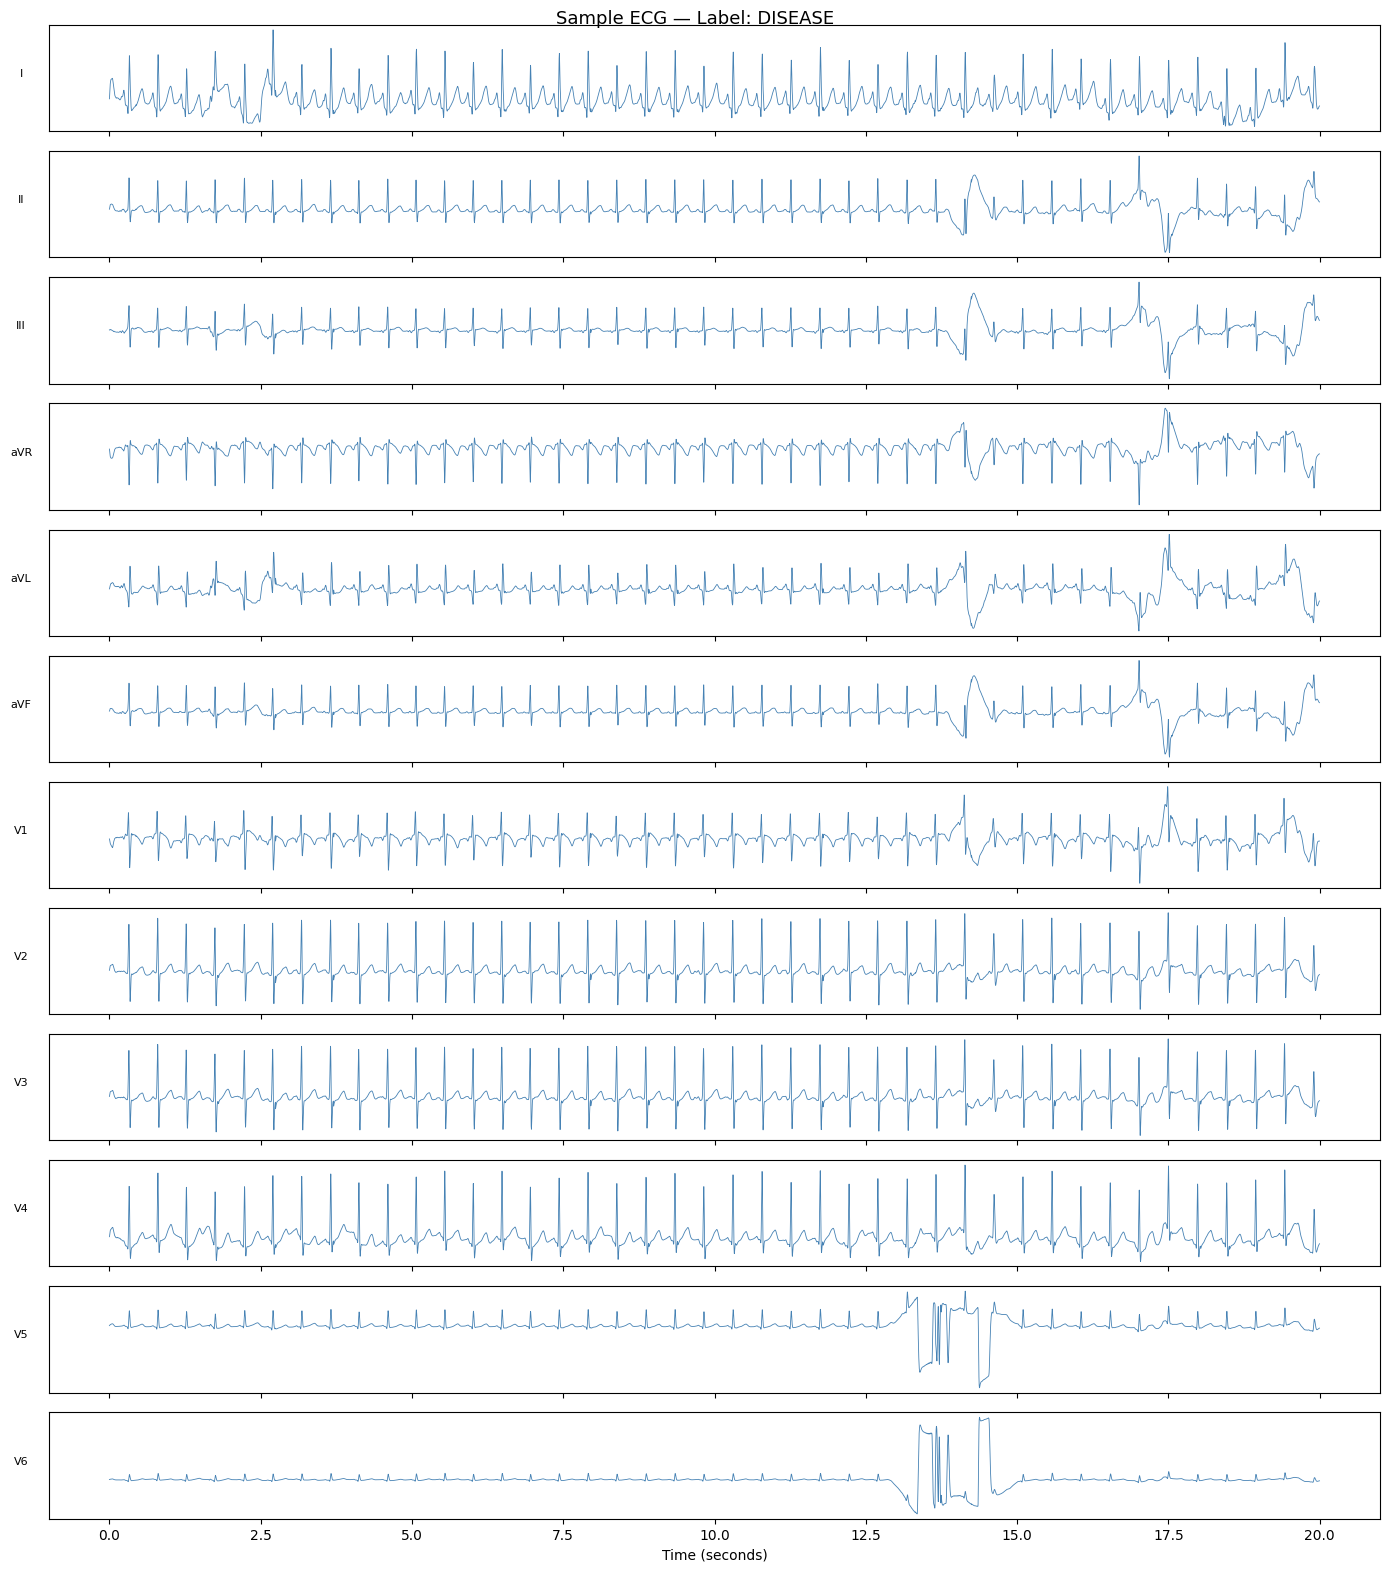

In [ ]:
sample_signal, sample_label = train_dataset[0]
signal_np = sample_signal.numpy()

LEAD_NAMES = ['I','II','III','aVR','aVL','aVF','V1','V2','V3','V4','V5','V6']
time_axis  = np.arange(FIXED_LENGTH) / 500   # convert to seconds

fig, axes = plt.subplots(12, 1, figsize=(14, 16), sharex=True)
for i, ax in enumerate(axes):
    ax.plot(time_axis, signal_np[i], linewidth=0.6, color='steelblue')
    ax.set_ylabel(LEAD_NAMES[i], fontsize=8, rotation=0, labelpad=20)
    ax.set_yticks([])

axes[-1].set_xlabel('Time (seconds)')
label_str = 'DISEASE' if sample_label.item() == 1 else 'OTHER'
fig.suptitle(f'Sample ECG — Label: {label_str}', fontsize=13)
plt.tight_layout()
plt.savefig('sample_ecg.png', dpi=150)
plt.show()

---
## Section 6 — CNN Architecture
A 4-block 1D CNN. Each block applies:
**Conv1d → BatchNorm → ReLU → MaxPool**

The filter slides along the **time axis** of each lead, detecting waveform
patterns (QRS shape, ST changes, T-wave morphology) regardless of where
they appear in the 10-second window.

`AdaptiveAvgPool1d(16)` at the end collapses variable-length feature maps
to a fixed 16-timestep representation before the classifier head.

In [ ]:
class PediatricECG_CNN(nn.Module):
    def __init__(self, n_leads=N_LEADS, n_classes=1):
        super().__init__()

        self.encoder = nn.Sequential(

            # Block 1 — detect low-level features (edges, peaks)
            nn.Conv1d(n_leads, 32, kernel_size=7, padding=3),
            nn.BatchNorm1d(32),
            nn.ReLU(),
            nn.MaxPool1d(kernel_size=2),        # 5000 → 2500

            # Block 2 — detect mid-level patterns (QRS complex shape)
            nn.Conv1d(32, 64, kernel_size=5, padding=2),
            nn.BatchNorm1d(64),
            nn.ReLU(),
            nn.MaxPool1d(kernel_size=2),        # 2500 → 1250

            # Block 3 — detect higher-level patterns (ST segment, T-wave)
            nn.Conv1d(64, 128, kernel_size=5, padding=2),
            nn.BatchNorm1d(128),
            nn.ReLU(),
            nn.MaxPool1d(kernel_size=2),        # 1250 → 625

            # Block 4 — detect rhythm-level patterns
            nn.Conv1d(128, 256, kernel_size=3, padding=1),
            nn.BatchNorm1d(256),
            nn.ReLU(),
            nn.AdaptiveAvgPool1d(16),           # 625 → 16 (fixed)
        )

        self.classifier = nn.Sequential(
            nn.Flatten(),                        # 256 × 16 = 4096
            nn.Linear(256 * 16, 128),
            nn.ReLU(),
            nn.Dropout(0.5),                     # regularisation
            nn.Linear(128, n_classes)            # raw logit output
        )

    def forward(self, x):
        # x: (batch, n_leads, timesteps)
        x = self.encoder(x)
        return self.classifier(x)    # Keep as (batch, 1) for SHAP explainer

# Instantiate and inspect
model = PediatricECG_CNN(n_leads=N_LEADS, n_classes=1).to(DEVICE)

# Count parameters
total_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"Model parameters: {total_params:,}")

# Verify forward pass shape
dummy = torch.zeros(2, N_LEADS, FIXED_LENGTH).to(DEVICE)
out   = model(dummy)
print(f"Input shape:  {dummy.shape}")
print(f"Output shape: {out.shape}   ← one logit per sample (binary)")

Model parameters: 678,177
Input shape:  torch.Size([2, 12, 10000])
Output shape: torch.Size([2, 1])   ← one logit per sample (binary)


---
## Section 7 — Training Loop with Early Stopping

### 7.1 Loss, optimiser, scheduler

In [ ]:
# BCEWithLogitsLoss = sigmoid + binary cross-entropy in one numerically stable step
criterion = nn.BCEWithLogitsLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3, weight_decay=1e-4)

# Reduce learning rate if val loss plateaus
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer, mode='min', factor=0.5, patience=3
)

print("Loss:      BCEWithLogitsLoss")
print("Optimiser: Adam  lr=1e-3  weight_decay=1e-4")
print("Scheduler: ReduceLROnPlateau  factor=0.5  patience=3")

Loss:      BCEWithLogitsLoss
Optimiser: Adam  lr=1e-3  weight_decay=1e-4
Scheduler: ReduceLROnPlateau  factor=0.5  patience=3


### 7.2 Train and eval functions

In [ ]:
def train_one_epoch(model, loader, optimizer, criterion, device):
    model.train()
    total_loss, correct, total = 0.0, 0, 0

    for signals, labels in loader:
        signals = signals.to(device)
        labels  = labels.to(device).unsqueeze(1)  # Reshape labels to (batch_size, 1)

        optimizer.zero_grad()
        logits = model(signals)
        loss   = criterion(logits, labels)
        loss.backward()
        optimizer.step()

        total_loss += loss.item()
        preds   = (torch.sigmoid(logits) > 0.5).float()
        correct += (preds == labels).sum().item()
        total   += labels.size(0)

    return total_loss / len(loader), correct / total


def evaluate(model, loader, criterion, device):
    model.eval()
    total_loss, correct, total = 0.0, 0, 0
    all_probs, all_labels = [], []

    with torch.no_grad():
        for signals, labels in loader:
            signals = signals.to(device)
            labels  = labels.to(device).unsqueeze(1)  # Reshape labels to (batch_size, 1)

            logits = model(signals)
            loss   = criterion(logits, labels)
            probs  = torch.sigmoid(logits)

            total_loss += loss.item()
            preds   = (probs > 0.5).float()
            correct += (preds == labels).sum().item()
            total   += labels.size(0)

            all_probs.extend(probs.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())

    return (
        total_loss / len(loader),
        correct / total,
        np.array(all_probs),
        np.array(all_labels)
    )

### 7.3 Run training

In [ ]:
EPOCHS        = 40 #40
PATIENCE      = 7       # stop if val loss doesn't improve for 7 epochs
BEST_MODEL_PT = 'best_cnn_pediatric_ecg.pt'

best_val_loss = float('inf')
no_improve    = 0
history       = {'train_loss': [], 'val_loss': [],
                 'train_acc':  [], 'val_acc':  []}

print(f"Training on {DEVICE} for up to {EPOCHS} epochs (patience={PATIENCE})\n")
print(f"{'Epoch':>5} | {'Train Loss':>10} | {'Train Acc':>9} | {'Val Loss':>8} | {'Val Acc':>7}")
print("-" * 55)

for epoch in range(1, EPOCHS + 1):

    train_loss, train_acc = train_one_epoch(
        model, train_loader, optimizer, criterion, DEVICE
    )
    val_loss, val_acc, val_probs, val_labels = evaluate(
        model, val_loader, criterion, DEVICE
    )
    scheduler.step(val_loss)

    history['train_loss'].append(train_loss)
    history['val_loss'].append(val_loss)
    history['train_acc'].append(train_acc)
    history['val_acc'].append(val_acc)

    print(f"{epoch:>5} | {train_loss:>10.4f} | {train_acc:>9.4f} | "
          f"{val_loss:>8.4f} | {val_acc:>7.4f}")

    # Save best model
    if val_loss < best_val_loss:
        best_val_loss = val_loss
        no_improve    = 0
        torch.save(model.state_dict(), BEST_MODEL_PT)
    else:
        no_improve += 1
        if no_improve >= PATIENCE:
            print(f"\nEarly stopping triggered at epoch {epoch}")
            break

print(f"\nBest val loss: {best_val_loss:.4f}")
print(f"Model saved to: {BEST_MODEL_PT}")

Training on cuda for up to 40 epochs (patience=7)

Epoch | Train Loss | Train Acc | Val Loss | Val Acc
-------------------------------------------------------
    1 |     0.6039 |    0.6761 |   0.6074 |  0.7292
    2 |     0.5898 |    0.6905 |   0.5234 |  0.7683
    3 |     0.5873 |    0.7019 |   0.6293 |  0.6708
    4 |     0.5775 |    0.7018 |   0.7505 |  0.5671
    5 |     0.5796 |    0.6921 |   0.5676 |  0.7136
    6 |     0.5711 |    0.7089 |   0.6449 |  0.6626
    7 |     0.5515 |    0.7269 |   0.5339 |  0.7667
    8 |     0.5533 |    0.7186 |   0.6444 |  0.6675
    9 |     0.5428 |    0.7268 |   0.5577 |  0.7226

Early stopping triggered at epoch 9

Best val loss: 0.5234
Model saved to: best_cnn_pediatric_ecg.pt


### 7.4 Training curves

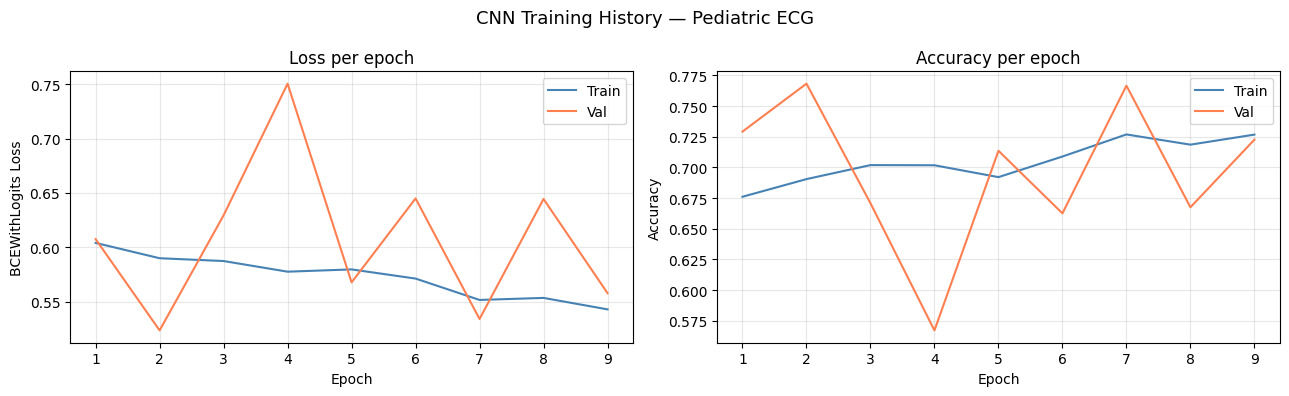

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

epochs_ran = range(1, len(history['train_loss']) + 1)

axes[0].plot(epochs_ran, history['train_loss'], label='Train', color='steelblue')
axes[0].plot(epochs_ran, history['val_loss'],   label='Val',   color='coral')
axes[0].set_title('Loss per epoch')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('BCEWithLogits Loss')
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].plot(epochs_ran, history['train_acc'], label='Train', color='steelblue')
axes[1].plot(epochs_ran, history['val_acc'],   label='Val',   color='coral')
axes[1].set_title('Accuracy per epoch')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Accuracy')
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.suptitle('CNN Training History — Pediatric ECG', fontsize=13)
plt.tight_layout()
plt.savefig('training_curves.png', dpi=150)
plt.show()

---
## Section 8 — Final Evaluation on Test Set
> ⚠️ Run this section only once — after all training and tuning is complete.

In [ ]:
# Load best saved model
model.load_state_dict(torch.load(BEST_MODEL_PT, map_location=DEVICE))

test_loss, test_acc, test_probs, test_labels = evaluate(
    model, test_loader, criterion, DEVICE
)
test_preds = (test_probs > 0.5).astype(int)

print("=== Test Set Results ===")
print(classification_report(
    test_labels, test_preds,
    target_names=['OTHER', 'DISEASE'],
    digits=4
))
roc_auc = roc_auc_score(test_labels, test_probs)
print(f"ROC-AUC:  {roc_auc:.4f}")
print(f"Test Loss: {test_loss:.4f}")
print(f"Test Acc:  {test_acc:.4f}")

=== Test Set Results ===
              precision    recall  f1-score   support

       OTHER     0.8407    0.8176    0.8290      1897
     DISEASE     0.4437    0.4842    0.4631       570

    accuracy                         0.7406      2467
   macro avg     0.6422    0.6509    0.6460      2467
weighted avg     0.7489    0.7406    0.7444      2467

ROC-AUC:  0.7204
Test Loss: 0.5647
Test Acc:  0.7406


### 8.1 Confusion matrix

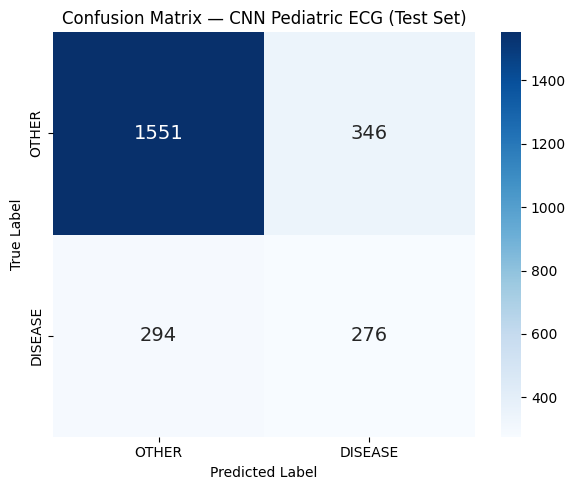

True Positives  (DISEASE correctly detected): 276
False Negatives (DISEASE missed):             294  ← clinical risk
True Negatives  (OTHER correctly rejected):   1551
False Positives (OTHER wrongly flagged):      346

Sensitivity (Recall for DISEASE): 0.4842
Specificity:                       0.8176


In [ ]:
cm = confusion_matrix(test_labels, test_preds)

plt.figure(figsize=(6, 5))
sns.heatmap(
    cm, annot=True, fmt='d', cmap='Blues',
    xticklabels=['OTHER', 'DISEASE'],
    yticklabels=['OTHER', 'DISEASE'],
    annot_kws={'size': 14}
)
plt.title('Confusion Matrix — CNN Pediatric ECG (Test Set)', fontsize=12)
plt.ylabel('True Label')
plt.xlabel('Predicted Label')
plt.tight_layout()
plt.savefig('confusion_matrix_cnn.png', dpi=150)
plt.show()

tn, fp, fn, tp = cm.ravel()
print(f"True Positives  (DISEASE correctly detected): {tp}")
print(f"False Negatives (DISEASE missed):             {fn}  ← clinical risk")
print(f"True Negatives  (OTHER correctly rejected):   {tn}")
print(f"False Positives (OTHER wrongly flagged):      {fp}")
print(f"\nSensitivity (Recall for DISEASE): {tp/(tp+fn):.4f}")
print(f"Specificity:                       {tn/(tn+fp):.4f}")

### 8.2 ROC curve

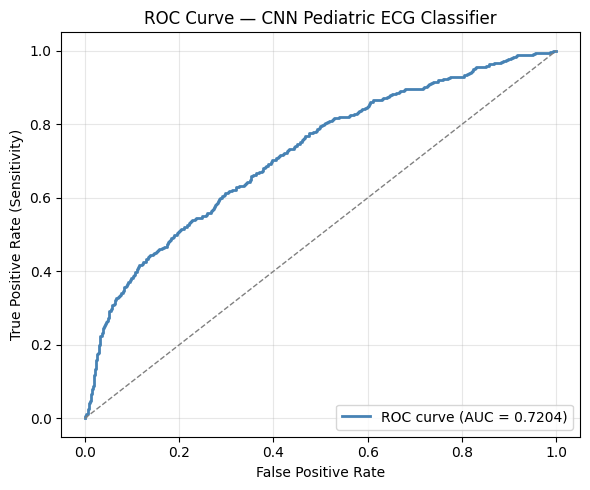

In [ ]:
from sklearn.metrics import roc_curve, auc

fpr, tpr, _ = roc_curve(test_labels, test_probs)
roc_auc_val = auc(fpr, tpr)

plt.figure(figsize=(6, 5))
plt.plot(fpr, tpr, color='steelblue', lw=2,
         label=f'ROC curve (AUC = {roc_auc_val:.4f})')
plt.plot([0,1],[0,1], color='gray', linestyle='--', lw=1)
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate (Sensitivity)')
plt.title('ROC Curve — CNN Pediatric ECG Classifier')
plt.legend(loc='lower right')
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig('roc_curve_cnn.png', dpi=150)
plt.show()

---
## Section 9 — XAI: SHAP GradientExplainer Saliency Maps
For CNNs we use `shap.GradientExplainer` instead of `KernelExplainer`.

It computes gradients of the output with respect to each input timestep,
identifying **which parts of the ECG waveform** most influenced the prediction.
This is much faster than KernelExplainer on high-dimensional waveform inputs.

> **Clinical meaning**: A high SHAP value at timestep 500 means the signal
> amplitude across all 12 leads at that moment strongly pushed the model
> toward DISEASE or OTHER.

In [ ]:
import shap

model.eval()
model.to(DEVICE)

# Use 50 training samples as background (SHAP baseline)
background_signals = torch.stack(
    [train_dataset[i][0] for i in range(50)]
).to(DEVICE)

# Collect 20 test samples for explanation
test_signals_list  = []
test_labels_list   = []
for i in range(min(20, len(test_dataset))):
    sig, lbl = test_dataset[i]
    test_signals_list.append(sig)
    test_labels_list.append(lbl.item())

test_signals_shap = torch.stack(test_signals_list).to(DEVICE)

print("Computing SHAP GradientExplainer values...")
explainer   = shap.GradientExplainer(model, background_signals)
# explainer.shap_values returns a list of arrays, one for each model output.
# Since our model outputs a single logit (n_classes=1), we take the first element.
shap_values = explainer.shap_values(test_signals_shap)[0]
# shap_values shape: (n_samples, n_leads, timesteps, 1) -> we need to squeeze the last dimension

print(f"SHAP values shape: {np.array(shap_values).shape}")
print("Done ✓")

Computing SHAP GradientExplainer values...
SHAP values shape: (12, 10000, 1)
Done ✓


### 9.1 Mean absolute SHAP across leads — global feature importance

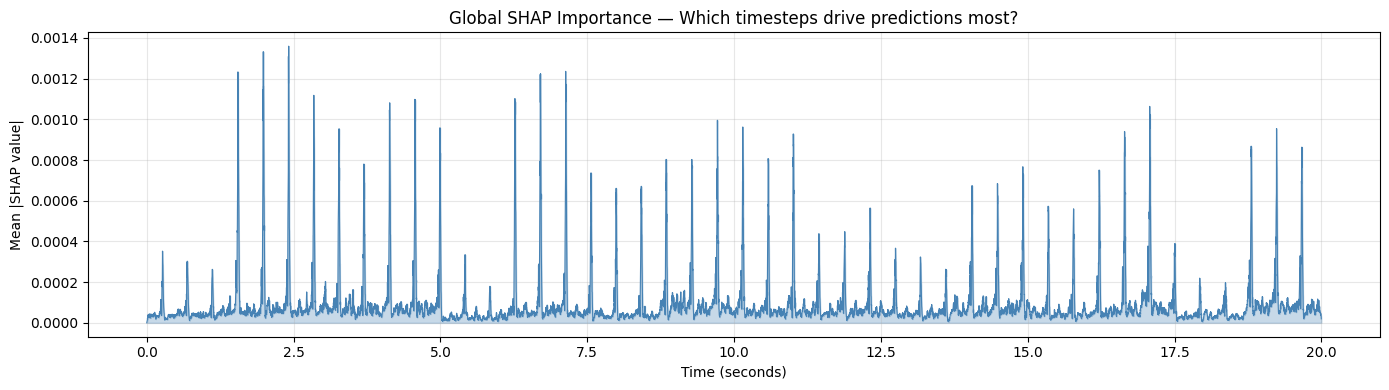

In [ ]:
# Average absolute SHAP across all 20 test samples and all 12 leads
# Result: importance per timestep
shap_arr       = shap_values.squeeze(-1) # Remove the last dimension of size 1
mean_abs_shap  = np.abs(shap_arr).mean(axis=0)  # Average only over leads to get importance per timestep

time_axis = np.arange(FIXED_LENGTH) / 500

plt.figure(figsize=(14, 4))
plt.plot(time_axis, mean_abs_shap, color='steelblue', linewidth=0.8)
plt.fill_between(time_axis, mean_abs_shap, alpha=0.3, color='steelblue')
plt.xlabel('Time (seconds)')
plt.ylabel('Mean |SHAP value|')
plt.title('Global SHAP Importance — Which timesteps drive predictions most?')
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig('shap_global_timeseries.png', dpi=150)
plt.show()

---
## Pipeline Complete ✓

| Section | Description |
|---------|-------------|
| 1 | Unzip dataset, install libraries, imports |
| 2 | Load attribute dictionary, create binary labels (DISEASE / OTHER) |
| 3 | Drop 9-lead records, filter unqualified SQI |
| 4 | Patient-level split — 60% train / 20% val / 20% test |
| 5 | PyTorch Dataset (truncate/pad to 5,000 timesteps), weighted DataLoader |
| 6 | 4-block 1D CNN — Conv → BN → ReLU → Pool, binary classifier head |
| 7 | Training — BCEWithLogitsLoss, Adam, ReduceLROnPlateau, early stopping |
| 8 | Evaluation — accuracy, ROC-AUC, confusion matrix, sensitivity/specificity |
| 9 | XAI — SHAP GradientExplainer saliency maps per timestep and per lead |

### Key results to report
- Test ROC-AUC (primary metric for imbalanced binary classification)
- Sensitivity — how many DISEASE cases were caught (clinically critical)
- Specificity — how many OTHER cases were correctly rejected
- SHAP heatmap — which ECG region and leads drove the prediction

### Suggested next steps
1. Try `FIXED_LENGTH = 10000` (20 seconds) — does more signal help?
2. Compare against a BPN baseline (flatten → MLPClassifier) on the same split
3. Add age and sex as auxiliary features alongside the waveform
4. Extend to multiclass — separate myocarditis, congenital disease, Kawasaki